## Superstore Sales Dataset Analysis

## 1. Setup
Imports, project paths, and logging. Paths are built from the project root, so the notebook works on any machine as long as it is run from the `notebooks/` folder. Every cleaning step is logged to the screen and to `logs/preprocessing.log`, and figures are saved to `reports/figures/`.

In [1]:
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path("..").resolve()
RAW_PATH = ROOT / "data" / "raw" / "Superstore Sales Dataset.csv"
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
LOG_DIR = ROOT / "logs"
for d in (PROCESSED_DIR, FIG_DIR, LOG_DIR):
    d.mkdir(parents=True, exist_ok=True)

logger = logging.getLogger("superstore")
logger.setLevel(logging.INFO)
logger.handlers.clear()
fmt = logging.Formatter("%(asctime)s | %(levelname)s | %(message)s")
for h in (logging.StreamHandler(), logging.FileHandler(LOG_DIR / "preprocessing.log", mode="w")):
    h.setFormatter(fmt)
    logger.addHandler(h)

def save_fig(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    logger.info("Saved figure %s", path.name)

## 2. Load and profile the raw data
The raw file stays untouched in `data/raw/`. Each row is one **order line** (one product within an order), so an order with several products appears on several rows. The file has 9,800 rows and 18 columns covering January 2015 to December 2018.

Sales is the **only numeric measure**: there is no Profit, Quantity or Discount column, so all analysis in later weeks is about sales, not profitability.

In [3]:
try:
    raw = pd.read_csv(RAW_PATH)
except FileNotFoundError:
    logger.error("Raw file not found at %s", RAW_PATH)
    raise

print(f"Shape: {raw.shape[0]} rows x {raw.shape[1]} columns")
raw.head()

Shape: 9800 rows x 18 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37


In [4]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

In [5]:
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_missing": raw.isnull().sum(),
    "n_unique": raw.nunique()
})
profile

,dtype,n_missing,n_unique
Row ID,int64,0,9800
Order ID,object,0,4922
Order Date,object,0,1230
Ship Date,object,0,1326
Ship Mode,object,0,4
Customer ID,object,0,793
Customer Name,object,0,793
Segment,object,0,3
Country,object,0,1
City,object,0,529


**Observations:** `Postal Code` is stored as a decimal number and has 11 missing values. `Order Date` and `Ship Date` are text. The remaining columns are complete, and the file holds about 800 customers, about 1,900 products and 49 states.

In [6]:
raw.describe()

,Row ID,Postal Code,Sales
count,"9,800.00","9,789.00","9,800.00"
mean,"4,900.50","55,273.32",230.77
std,"2,829.16","32,041.22",626.65
min,1.00,"1,040.00",0.44
25%,"2,450.75","23,223.00",17.25
50%,"4,900.50","58,103.00",54.49
75%,"7,350.25","90,008.00",210.61
max,"9,800.00","99,301.00","22,638.48"


## 3. Data-quality findings
Each check below leads to one of three outcomes: **fix** it, **keep and document** it, or **confirm it is clean**.

### 3.1 Missing Values

In [7]:
missing = raw.isnull().sum()
missing = missing[missing > 0]
print("Columns with missing values:")
print(missing.to_string())
print()
print("Rows affected:")
raw[raw["Postal Code"].isnull()][["Row ID", "City", "State", "Postal Code"]]

Columns with missing values:
Postal Code    11

Rows affected:


,Row ID,City,State,Postal Code
2234,2235,Burlington,Vermont,NaN
5274,5275,Burlington,Vermont,NaN
8798,8799,Burlington,Vermont,NaN
9146,9147,Burlington,Vermont,NaN
9147,9148,Burlington,Vermont,NaN
9148,9149,Burlington,Vermont,NaN
9386,9387,Burlington,Vermont,NaN
9387,9388,Burlington,Vermont,NaN
9388,9389,Burlington,Vermont,NaN
9389,9390,Burlington,Vermont,NaN


All 11 missing postal codes belong to **Burlington, Vermont**, a single known ZIP (05401), so they can be imputed safely with domain knowledge rather than dropped.

### 3.2 Date columns
As `.info()` showed, `Order Date` and `Ship Date` are loaded as text (`object`), not datetime, so they can't be sorted chronologically or used for date arithmetic. They are also in **day/month/year** format, so they must be converted with an explicit format (`%d/%m/%Y`) rather than letting pandas guess.

### 3.3 Duplicates and key consistency
Because each row is an order line, a repeated Order ID is normal. The questions that matter are:
- Is any row repeated in full? (We ignore `Row ID`, since it is a unique counter that would hide any duplicate.)
- Does the same product appear twice in the same order?
- Does each Product ID have exactly one name? (Required for the product dimension's primary key.)

In [8]:
print("Duplicate rows:", raw.duplicated().sum())
print("Duplicate order lines:", raw.drop("Row ID", axis=1).duplicated().sum())
print("Row ID unique:", raw["Row ID"].is_unique)
print("Repeated (Order ID, Product ID):", raw.duplicated(["Order ID", "Product ID"], keep=False).sum(), "rows")

Duplicate rows: 0
Duplicate order lines: 1
Row ID unique: True
Repeated (Order ID, Product ID): 16 rows


In [9]:
# repeated order lines
rep = raw[raw.duplicated(["Order ID", "Product ID"], keep=False)]
rep[["Row ID", "Order ID", "Product ID", "Sales"]].sort_values(["Order ID", "Row ID"])

,Row ID,Order ID,Product ID,Sales
6498,6499,CA-2016-103135,OFF-BI-10000069,135.09
6500,6501,CA-2016-103135,OFF-BI-10000069,90.06
350,351,CA-2017-129714,OFF-PA-10001970,24.56
352,353,CA-2017-129714,OFF-PA-10001970,49.12
1300,1301,CA-2017-137043,FUR-FU-10003664,572.76
1301,1302,CA-2017-137043,FUR-FU-10003664,286.38
9168,9169,CA-2017-140571,OFF-PA-10001954,319.76
9169,9170,CA-2017-140571,OFF-PA-10001954,45.68
7881,7882,CA-2018-118017,TEC-AC-10002006,76.75
7882,7883,CA-2018-118017,TEC-AC-10002006,102.34


**Decision:** a repeated Order ID is normal, since each row is one order line (one product in an order). What is unusual is the same product appearing twice in the same order. Seven of the eight pairs have different sales values, so they are treated as separate lines and **kept**. The pair (Row IDs 3406 and 3407) is identical in every column except `Row ID`, so it is treated as a probable duplicate entry and **Row 3407 is removed** (impact: $281.37 of $2.26M, one row).

### 3.3b Products with conflicting names

In [10]:
# One Product ID should have one product name (entity integrity)
names_per_id = raw.groupby("Product ID")["Product Name"].nunique()
print("Product IDs with more than one product name:", (names_per_id > 1).sum())

Product IDs with more than one product name: 32


In [11]:
conflict_ids = names_per_id[names_per_id > 1].index
(raw[raw["Product ID"].isin(conflict_ids)]
    .groupby(["Product ID", "Product Name"]).size()
    .rename("n_rows").reset_index())

,Product ID,Product Name,n_rows
0,FUR-BO-10002213,DMI Eclipse Executive Suite Bookcases,6
1,FUR-BO-10002213,"Sauder Forest Hills Library, Woodland Oak Finish",4
2,FUR-CH-10001146,"Global Task Chair, Black",5
3,FUR-CH-10001146,"Global Value Mid-Back Manager's Chair, Gray",9
4,FUR-FU-10001473,DAX Wood Document Frame,9
...,...,...,...
59,TEC-PH-10002200,Samsung Galaxy Note 2,2
60,TEC-PH-10002310,Panasonic KX T7731-B Digital phone,2
61,TEC-PH-10002310,Plantronics Calisto P620-M USB Wireless Speake...,4
62,TEC-PH-10004531,AT&T CL2909,3


The same Product ID appears with different names. A product dimension needs **one name per ID** (primary key), so we will keep the most frequent name per ID.

### 3.4 Outliers in Sales

In [12]:
q1, q3 = raw["Sales"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print(f"Q1 = {q1:,.2f}, Q3 = {q3:,.2f}, IQR upper boundary = {upper:,.2f}")
n_out = (raw["Sales"] > upper).sum()
print(f"Rows above upper boundary: {n_out} ({n_out / len(raw):.1%})")
raw.nlargest(5, "Sales")[["Order ID", "Product Name", "Category", "Sales"]]

Q1 = 17.25, Q3 = 210.61, IQR upper boundary = 500.64
Rows above upper boundary: 1145 (11.7%)


,Order ID,Product Name,Category,Sales
2697,CA-2015-145317,Cisco TelePresence System EX90 Videoconferenci...,Technology,"22,638.48"
6826,CA-2017-118689,Canon imageCLASS 2200 Advanced Copier,Technology,"17,499.95"
8153,CA-2018-140151,Canon imageCLASS 2200 Advanced Copier,Technology,"13,999.96"
2623,CA-2018-127180,Canon imageCLASS 2200 Advanced Copier,Technology,"11,199.97"
4190,CA-2018-166709,Canon imageCLASS 2200 Advanced Copier,Technology,"10,499.97"


The largest values are genuinely high-priced items (the top five are all in Technology), not data-entry errors. **Decision:** keep them and add an `is_sales_outlier` flag (sales above Q3 + 1.5 x IQR). They matter: the 1,145 flagged rows (11.7% of rows) generate about 64% of total sales.

### 3.5 Summary of findings and decisions

| Issue | Evidence | Decision |
|---|---|---|
| Missing postal codes | 11 rows, all Burlington, Vermont | Imputed ZIP 05401 |
| Dates stored as text, day/month/year | `object` dtype | Parsed with explicit format `%d/%m/%Y` |
| Postal code stored as a number | Leading zeros would be lost | Converted to 5-character text |
| Duplicate order line | Row IDs 3406 and 3407 identical except `Row ID` | Removed Row 3407 ($281.37) |
| Same product twice in one order | 7 pairs remain, with different sales values | Kept as separate lines |
| Product IDs with conflicting names | 32 IDs | Standardised to the most frequent name |
| High-value sales | 1,145 rows above the IQR fence | Kept and flagged |
| Exact duplicates, negative sales, ship before order | None found | Confirmed clean |

## 4. Cleaning pipeline
All cleaning lives in one reusable class, `SuperstoreCleaner`. Each method is one step, returns `self` so steps chain together, and writes an entry to a cleaning log.

| Order | Method | Purpose |
|---|---|---|
| 1 | `load` | Read the raw CSV (with error handling) |
| 2 | `standardize_columns` | snake_case column names |
| 3 | `trim_text` | Strip leading/trailing spaces |
| 4 | `remove_duplicates` | Drop rows identical except `row_id` |
| 5 | `parse_dates` | Convert to datetime with an explicit format |
| 6 | `fix_postal_codes` | Impute missing ZIPs, store as 5-character text |
| 7 | `resolve_product_names` | One name per Product ID |
| 8 | `add_features` | `ship_days`, `order_year`, `order_quarter`, `order_month`, `year_month` |
| 9 | `flag_outliers` | `is_sales_outlier` (IQR rule) |
| 10 | `note_repeated_lines` | Log the repeated order/product pairs |
| 11 | `validate` | Stop with an error if any rule fails |

In [13]:
class SuperstoreCleaner:
    known_zips = {("Burlington", "Vermont"): "05401"}

    def __init__(self, path):
        self.path = Path(path)
        self.df = None
        self.log = [] # list of dicts: issue / rows / action
        self.product_name_conflicts = None
        self.outlier_threshold = None

    # helpers
    def _record(self, issue, rows, action):
        self.log.append({"issue": issue, "rows_affected": int(rows), "action": action})
        logger.info("%s | rows=%s | %s", issue, rows, action)

    # steps
    def load(self):
        try:
            self.df = pd.read_csv(self.path)
        except FileNotFoundError:
            logger.error("File not found: %s", self.path)
            raise
        logger.info("Loaded %s rows, %s columns", *self.df.shape)
        return self

    def standardize_columns(self):
        self.df.columns = (self.df.columns.str.strip().str.lower().str.replace(r"[\s-]+", "_", regex=True))
        self._record("Inconsistent column names", len(self.df.columns), "Converted to snake_case")
        return self

    def trim_text(self):
        changed = 0
        for col in self.df.columns:
            if pd.api.types.is_string_dtype(self.df[col]):
                stripped = self.df[col].str.strip()
                changed += int((stripped != self.df[col]).sum())
                self.df[col] = stripped
        self._record("Leading/trailing whitespace in text", changed, "Applied str.strip()")
        return self

    def remove_duplicates(self):
        cols = [c for c in self.df.columns if c != "row_id"]
        dup_mask = self.df.duplicated(subset=cols, keep="first")
        removed_ids = self.df.loc[dup_mask, "row_id"].tolist()
        self.df = self.df.loc[~dup_mask].reset_index(drop=True)
        self._record("Duplicate order lines (identical except row_id)", len(removed_ids), f"Removed row_id(s) {removed_ids}; kept first occurrence")
        return self

    def parse_dates(self):
        for col in ("order_date", "ship_date"):
            self.df[col] = pd.to_datetime(self.df[col], format="%d/%m/%Y", errors="raise")
        self._record("Dates stored as day/month/year text", len(self.df), "Parsed order_date and ship_date with explicit format %d/%m/%Y")
        return self

    def fix_postal_codes(self):
        missing = self.df["postal_code"].isnull()
        for (city, state), zip_code in self.known_zips.items():
            m = missing & (self.df["city"] == city) & (self.df["state"] == state)
            self.df.loc[m, "postal_code"] = int(zip_code)
        still_missing = self.df["postal_code"].isnull().sum()
        if still_missing:
            raise ValueError(f"{still_missing} postal codes still missing")
        self.df["postal_code"] = self.df["postal_code"].astype(int).astype(str).str.zfill(5)
        self._record("Missing postal codes (Burlington, Vermont)", missing.sum(), "Imputed ZIP 05401; converted postal_code to 5-character text (keeps leading zeros)")
        return self

    def resolve_product_names(self):
        g = self.df.groupby("product_id")["product_name"]
        conflict_ids = g.nunique()[lambda s: s > 1].index
        self.product_name_conflicts = (self.df[self.df["product_id"].isin(conflict_ids)]
                                       .groupby(["product_id", "product_name"]).size()
                                       .rename("n_rows").reset_index())
        most_frequent = g.agg(lambda s: s.mode().iloc[0])
        self.df["product_name"] = self.df["product_id"].map(most_frequent)
        affected = self.df["product_id"].isin(conflict_ids).sum()
        self._record("Product IDs with conflicting names", affected, f"{len(conflict_ids)} IDs standardised to their most frequent name")
        return self

    def add_features(self):
        d = self.df
        d["ship_days"] = (d["ship_date"] - d["order_date"]).dt.days
        d["order_year"] = d["order_date"].dt.year
        d["order_quarter"] = d["order_date"].dt.quarter
        d["order_month"] = d["order_date"].dt.month
        d["year_month"] = d["order_date"].dt.to_period("M").astype(str)
        self._record("Feature engineering", len(d), "Added ship_days, order_year, order_quarter, order_month, year_month")
        return self

    def flag_outliers(self):
        q1, q3 = self.df["sales"].quantile([0.25, 0.75])
        self.outlier_threshold = q3 + 1.5 * (q3 - q1)
        self.df["is_sales_outlier"] = self.df["sales"] > self.outlier_threshold
        self._record("High-value sales (IQR outliers)", self.df["is_sales_outlier"].sum(), f"Flagged sales > {self.outlier_threshold:,.2f}; NOT removed (valid big-value orders)")
        return self

    def note_repeated_lines(self):
        n = self.df.duplicated(["order_id", "product_id"], keep=False).sum()
        self._record("Repeated (order_id, product_id) lines", n, "Kept: separate order lines with different row_id; documented")
        return self

    def validate(self):
        d = self.df
        checks = {
            "no missing values": d.isnull().sum().sum() == 0,
            "row_id unique": d["row_id"].is_unique,
            "no exact duplicate rows": not d.duplicated().any(),
            "no duplicate rows (ignoring row_id)": not d.drop(columns="row_id").duplicated().any(),
            "ship_date >= order_date": (d["ship_date"] >= d["order_date"]).all(),
            "sales > 0": (d["sales"] > 0).all(),
            "postal codes are 5 chars": (d["postal_code"].str.len() == 5).all(),
            "1 name per product_id": d.groupby("product_id")["product_name"].nunique().max() == 1,
            "1 segment per customer": d.groupby("customer_id")["segment"].nunique().max() == 1,
            "1 region per state": d.groupby("state")["region"].nunique().max() == 1,
            "1 category per product_id": d.groupby("product_id")[["category", "sub_category"]].nunique().max().max() == 1
        }
        for name, ok in checks.items():
            if ok:
                logger.info("Validation %-28s %s", name, "PASS")
            else:
                logger.error("Validation %-28s %s", name, "FAIL")
        failed = [k for k, ok in checks.items() if not ok]
        if failed:
            raise AssertionError(f"Validation failed: {failed}")
        self.validation = pd.Series(checks, name="passed")
        return self

    def run(self):
        return(self.load().standardize_columns().trim_text().remove_duplicates().parse_dates()
               .fix_postal_codes().resolve_product_names().add_features().flag_outliers()
               .note_repeated_lines().validate())


cleaner = SuperstoreCleaner(RAW_PATH).run()
df = cleaner.df
print(f"Clean shape: {df.shape}")

2026-11-15 21:29:17,387 | INFO | Loaded 9800 rows, 18 columns
2026-11-15 21:29:17,389 | INFO | Inconsistent column names | rows=18 | Converted to snake_case
2026-11-15 21:29:17,418 | INFO | Leading/trailing whitespace in text | rows=0 | Applied str.strip()
2026-11-15 21:29:17,431 | INFO | Duplicate order lines (identical except row_id) | rows=1 | Removed row_id(s) [3407]; kept first occurrence
2026-11-15 21:29:17,440 | INFO | Dates stored as day/month/year text | rows=9799 | Parsed order_date and ship_date with explicit format %d/%m/%Y
2026-11-15 21:29:17,446 | INFO | Missing postal codes (Burlington, Vermont) | rows=11 | Imputed ZIP 05401; converted postal_code to 5-character text (keeps leading zeros)


2026-11-15 21:29:17,548 | INFO | Product IDs with conflicting names | rows=331 | 32 IDs standardised to their most frequent name
2026-11-15 21:29:17,554 | INFO | Feature engineering | rows=9799 | Added ship_days, order_year, order_quarter, order_month, year_month
2026-11-15 21:29:17,556 | INFO | High-value sales (IQR outliers) | rows=1145 | Flagged sales > 500.56; NOT removed (valid big-value orders)
2026-11-15 21:29:17,558 | INFO | Repeated (order_id, product_id) lines | rows=14 | Kept: separate order lines with different row_id; documented
2026-11-15 21:29:17,588 | INFO | Validation no missing values            PASS
2026-11-15 21:29:17,588 | INFO | Validation row_id unique                PASS
2026-11-15 21:29:17,588 | INFO | Validation no exact duplicate rows      PASS
2026-11-15 21:29:17,589 | INFO | Validation no duplicate rows (ignoring row_id) PASS
2026-11-15 21:29:17,589 | INFO | Validation ship_date >= order_date      PASS
2026-11-15 21:29:17,589 | INFO | Validation sales > 0  

Clean shape: (9799, 24)


### 4.1 Cleaning log

In [14]:
cleaning_log = pd.DataFrame(cleaner.log)
cleaning_log.to_csv(ROOT / "reports" / "cleaning_log.csv", index=False)
cleaning_log

,issue,rows_affected,action
0,Inconsistent column names,18,Converted to snake_case
1,Leading/trailing whitespace in text,0,Applied str.strip()
2,Duplicate order lines (identical except row_id),1,Removed row_id(s) [3407]; kept first occurrence
3,Dates stored as day/month/year text,9799,Parsed order_date and ship_date with explicit ...
4,"Missing postal codes (Burlington, Vermont)",11,Imputed ZIP 05401; converted postal_code to 5-...
5,Product IDs with conflicting names,331,32 IDs standardised to their most frequent name
6,Feature engineering,9799,"Added ship_days, order_year, order_quarter, or..."
7,High-value sales (IQR outliers),1145,Flagged sales > 500.56; NOT removed (valid big...
8,"Repeated (order_id, product_id) lines",14,Kept: separate order lines with different row_...


In [15]:
cleaner.validation.to_frame()

,passed
no missing values,True
row_id unique,True
no exact duplicate rows,True
no duplicate rows (ignoring row_id),True
ship_date >= order_date,True
sales > 0,True
postal codes are 5 chars,True
1 name per product_id,True
1 segment per customer,True
1 region per state,True


### 4.2 Data dictionary (24 columns, 9,799 rows)

| Column | Type | Description | Origin |
|---|---|---|---|
| `row_id` | int | Unique order-line identifier | Original |
| `order_id` | text | Order identifier (one order has one or more lines) | Original |
| `order_date`, `ship_date` | date | Order and shipping dates | Original (re-typed) |
| `ship_mode` | text | Same Day, First Class, Second Class, Standard Class | Original |
| `customer_id`, `customer_name` | text | Customer key and name | Original |
| `segment` | text | Consumer, Corporate, Home Office | Original |
| `country`, `state`, `city` | text | Delivery location | Original |
| `postal_code` | text (5) | ZIP code, text to keep leading zeros | Original (fixed) |
| `region` | text | Central, East, South, West | Original |
| `product_id`, `product_name` | text | Product key and name | Original (names standardised) |
| `category`, `sub_category` | text | Product hierarchy | Original |
| `sales` | decimal | Sales amount of the order line | Original |
| `ship_days` | int | Days from order to shipment | Engineered |
| `order_year`, `order_quarter`, `order_month` | int | Date parts of `order_date` | Engineered |
| `year_month` | text | `YYYY-MM`, used for monthly trends and forecasting | Engineered |
| `is_sales_outlier` | bool | Sales above Q3 + 1.5 x IQR | Engineered |

## 5. Visual sanity checks

### 5.1 Sales distribution

2026-11-15 21:29:18,016 | INFO | Saved figure 01_sales_distribution.png


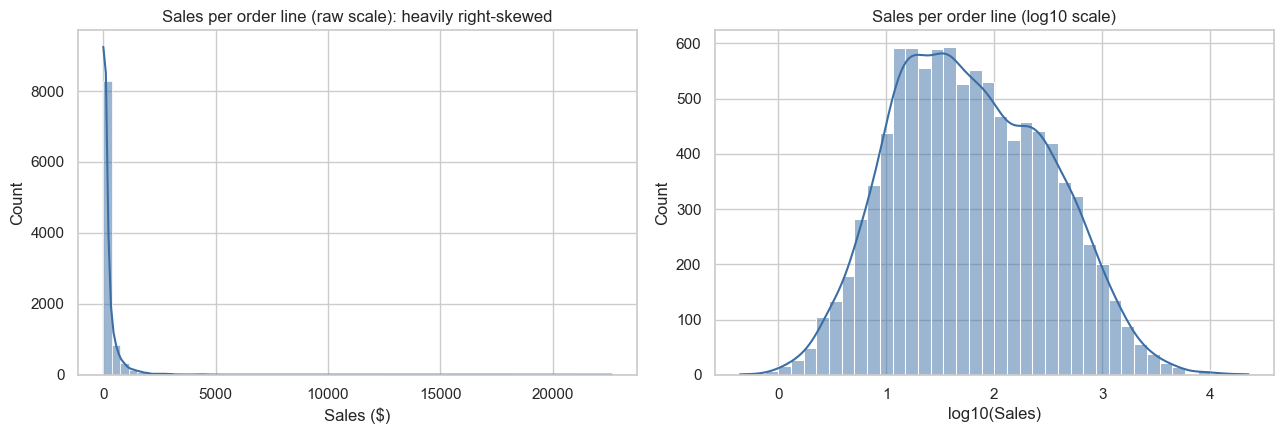

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["sales"], bins=60, kde=True, ax=axes[0], color="#3b6ea5")
axes[0].set_title("Sales per order line (raw scale): heavily right-skewed")
axes[0].set_xlabel("Sales ($)")
sns.histplot(np.log10(df["sales"]), bins=40, kde=True, ax=axes[1], color="#3b6ea5")
axes[1].set_title("Sales per order line (log10 scale)")
axes[1].set_xlabel("log10(Sales)")
plt.tight_layout()
save_fig(fig, "01_sales_distribution")
plt.show()

**Interpretation:** sales are heavily right-skewed. The median order line is about $54, while the mean is about $231, pulled up by a small number of very large orders. The log scale spreads out the small values so the shape is readable.

### 5.2 Outliers by category

2026-11-15 21:29:18,398 | INFO | Saved figure 02_sales_boxplot_by_category.png


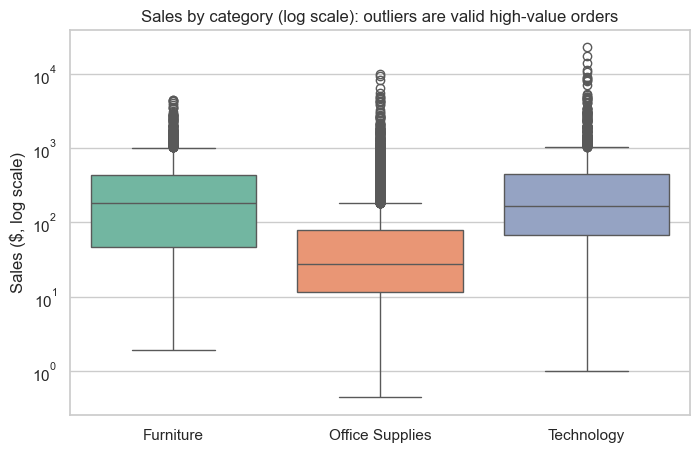

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="category", y="sales", ax=ax, palette="Set2", hue="category", legend=False)
ax.set_yscale("log")
ax.set_title("Sales by category (log scale): outliers are valid high-value orders")
ax.set_xlabel("")
ax.set_ylabel("Sales ($, log scale)")
save_fig(fig, "02_sales_boxplot_by_category")
plt.show()

**Interpretation:** Furniture and Technology have much higher typical sales (median about $183 and $168) than Office Supplies (about $27). About 22% of Furniture rows and 22% of Technology rows are flagged as outliers, compared with about 5% of Office Supplies rows. High values are normal for the first two categories, which is why they were kept.

### 5.3 Shipping time

2026-11-15 21:29:18,593 | INFO | Saved figure 03_ship_days_by_mode.png


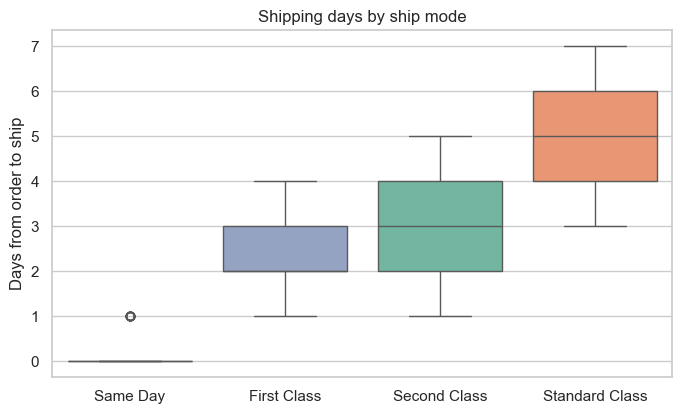

,min,mean,max
ship_mode,,,
Same Day,0,0.04,1
First Class,1,2.18,4
Second Class,1,3.25,5
Standard Class,3,5.01,7


In [18]:
order = ["Same Day", "First Class", "Second Class", "Standard Class"]
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df, x="ship_mode", y="ship_days", order=order, ax=ax, palette="Set2", hue="ship_mode", legend=False)
ax.set_title("Shipping days by ship mode")
ax.set_xlabel("")
ax.set_ylabel("Days from order to ship")
save_fig(fig, "03_ship_days_by_mode")
plt.show()
df.groupby("ship_mode")["ship_days"].agg(["min", "mean", "max"]).reindex(order)

**Interpretation:** shipping time is consistent with the ship mode: Same Day averages 0 days, First Class 2.2, Second Class 3.2 and Standard Class 5.0 (range 3-7). No order ships before it is placed. Standard Class is by far the most used mode (about 60% of order lines).

### 5.4 Monthly sales over time

2026-11-15 21:29:18,752 | INFO | Saved figure 04_monthly_sales.png


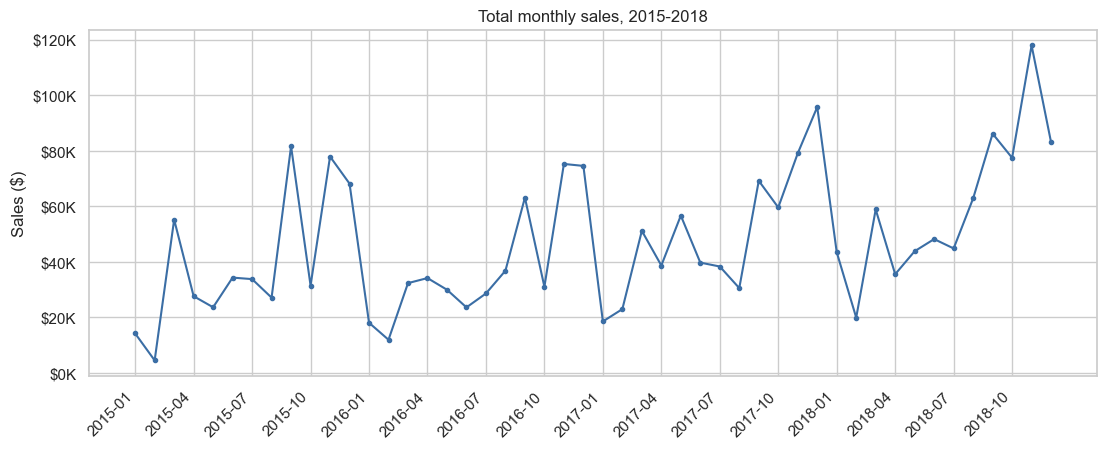

In [19]:
monthly = df.groupby("year_month")["sales"].sum()
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(monthly.index, monthly.values, marker="o", markersize=3, color="#3b6ea5")
ax.set_xticks(range(0, len(monthly), 3))
ax.set_xticklabels(monthly.index[::3], rotation=45, ha="right")
ax.set_title("Total monthly sales, 2015-2018")
ax.set_ylabel("Sales ($)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))
save_fig(fig, "04_monthly_sales")
plt.show()

**Interpretation:** sales dipped slightly in 2016 (-4.2%), then grew strongly in 2017 (+30.6%) and 2018 (+20.3%), reaching about $722K. There is clear seasonality: September, November and December together account for about 43% of annual sales, while January and February are the weakest months (about 4% and 3%). The strongest month was November 2018 (about $118K).

## 6. Bias and limitations review

In [20]:
bias = pd.concat({
    "region": df["region"].value_counts(normalize=True),
    "segment": df["segment"].value_counts(normalize=True),
    "category": df["category"].value_counts(normalize=True)
}).rename("share_of_rows").to_frame()
bias["share_of_rows"] = (bias["share_of_rows"] * 100).round(1).astype(str) + "%"
bias

share_of_rows
region   West                    32.0%
         East                    28.4%
         Central                 23.2%
         South                   16.3%
segment  Consumer                52.1%
         Corporate               30.1%
         Home Office             17.8%
category Office Supplies         60.3%
         Furniture               21.2%
         Technology              18.5%

**Observations**
- **Region:** West (32% of rows) and East (28%) dominate; South is smallest (16%). Sales shares are similar (West 31%, East 30%, Central 22%, South 17%), so the imbalance is real in value as well as in order counts.
- **Segment:** Consumer is just over half of all rows (52%) and of sales (51%).
- **Category:** Office Supplies is 60% of rows but only about 31% of sales, while Technology is 19% of rows and about 37% of sales.
- **Missing measures:** no Profit, Quantity or Discount, so profitability cannot be analysed.
- **Cleaning choices that could matter:** one probable duplicate was removed; 1,145 high-value sales were kept and flagged.

## 7. Export the cleaned dataset
The cleaned DataFrame is saved as `data/processed/superstore_clean.csv` (9,799 rows, 24 columns).

In [21]:
out_path = PROCESSED_DIR / "superstore_clean.csv"
df.to_csv(out_path, index=False)
print(f"Saved {out_path.name}: {df.shape[0]} rows x {df.shape[1]} columns")
print(list(df.columns))

Saved superstore_clean.csv: 9799 rows x 24 columns
['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'ship_days', 'order_year', 'order_quarter', 'order_month', 'year_month', 'is_sales_outlier']
